# 4.3 — Monte Carlo integration (I): importance sampling

Functions live in `functions.py`; this notebook runs them and keeps the data and figures.

In [26]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from functions import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [27]:
# Parameters (quote these in the report captions)
SEED = 1
N = 1_000_000          # (b) number of sampled points
N_LIST = np.unique(np.logspace(1, 5, 13).astype(int))   # (c) sample sizes N
N_RUNS = 1_000         # (c) independent runs per N
L_LIST = np.array([1, 1.5, 2, 3, 4, 6, 8, 12, 16])     # (d) half-widths L of the box [-L, L]^3
N_SWAP = 1_000_000     # (d) sampled points per box size

rng = np.random.default_rng(SEED)
set_plot_style()

## (a) Compute $I$ analytically.

In [28]:
import sympy as sp

x, y, z = sp.symbols("x y z", real=True)
integrand_sym = sp.exp(-(x**2 + y**2 + z**2) / 2) * (x + y + z)**2

# triple integral over R^3
I_sym = sp.simplify(sp.integrate(integrand_sym, (x, -sp.oo, sp.oo), (y, -sp.oo, sp.oo), (z, -sp.oo, sp.oo)))
I_EXACT = float(I_sym)   # used in (b)-(d)

print("I exact =", I_sym, "=", sp.N(I_sym, 8))
print("equal to 3 (2 pi)^(3/2):", sp.simplify(I_sym - 3 * (2 * sp.pi)**sp.Rational(3, 2)) == 0)

I exact = 6*sqrt(2)*pi**(3/2) = 47.248830
equal to 3 (2 pi)^(3/2): True


## (b) Use a Gaussian RNG to generate $x, y, z$ and estimate $I$; compare with the analytical result.

In [29]:
from scipy.stats import norm

x = norm.rvs(size=N, random_state=rng)
y = norm.rvs(size=N, random_state=rng)
z = norm.rvs(size=N, random_state=rng)

In [30]:
# exp(-r^2/2) = (2 pi)^{3/2} w(r)  ->  I = (2 pi)^{3/2} <(x+y+z)^2>
NORM = (2 * np.pi)**1.5
f = (x + y + z)**2

I_MC = NORM * f.mean()
I_ERR = NORM * f.std(ddof=1) / np.sqrt(N)      # standard error (independent samples)

print(f"I_MC    = {I_MC:.3f} ± {I_ERR:.3f}   (N = {N:,}, seed = {SEED})")
print(f"I_exact = {I_EXACT:.3f}")
print(f"(I_MC - I_exact) / error = {(I_MC - I_EXACT) / I_ERR:+.2f}")

I_MC    = 47.241 ± 0.067   (N = 1,000,000, seed = 1)
I_exact = 47.249
(I_MC - I_exact) / error = -0.12


## AI explains ddof
ddof counts how many quantities you estimated from the same data before computing the deviations. Here you estimated only one, the mean $\bar f$, so it is 1.

Why one estimated quantity costs one degree of freedom. The deviations from the sample mean always sum to zero:
$$\sum_{i=1}^N (f_i - \bar f) = 0 .$$
Once you know $N-1$ of them, the last one is fixed. So only $N-1$ independent deviations go into $\sum (f_i-\bar f)^2$, and dividing by $N-1$ makes $s^2$ unbiased:
$$\Big\langle \tfrac{1}{N-1}\textstyle\sum (f_i-\bar f)^2 \Big\rangle = \sigma^2 .$$

Here is the derivation:
$$\Big\langle \sum (f_i-\bar f)^2\Big\rangle = \sum \langle (f_i-\mu)^2\rangle - N\langle(\bar f-\mu)^2\rangle = N\sigma^2 - N\cdot\frac{\sigma^2}{N} = (N-1),\sigma^2 .$$
The term you subtract, $\sigma^2$, is exactly one variance of the mean, and that is the "1"

## (c) Compute the variance $\sigma^2$ of the estimate for different numbers of sampled points $N$, and show that $\sigma^2 \propto 1/N$.

fit:    sigma^2 = 4441 * N^(-1.000 ± 0.004)
theory: sigma^2 = 4465 / N
N =      10: sigma^2 =  475.0377 ± 21.2550,   N * sigma^2 =  4750 ± 213
N =      21: sigma^2 =  216.1026 ± 9.6692,   N * sigma^2 =  4538 ± 203
N =      46: sigma^2 =   97.3967 ± 4.3579,   N * sigma^2 =  4480 ± 200
N =     100: sigma^2 =   45.2799 ± 2.0260,   N * sigma^2 =  4528 ± 203
N =     215: sigma^2 =   18.9150 ± 0.8463,   N * sigma^2 =  4067 ± 182
N =     464: sigma^2 =    9.0530 ± 0.4051,   N * sigma^2 =  4201 ± 188
N =   1,000: sigma^2 =    4.1337 ± 0.1850,   N * sigma^2 =  4134 ± 185
N =   2,154: sigma^2 =    2.0870 ± 0.0934,   N * sigma^2 =  4495 ± 201
N =   4,641: sigma^2 =    0.9825 ± 0.0440,   N * sigma^2 =  4560 ± 204
N =  10,000: sigma^2 =    0.4478 ± 0.0200,   N * sigma^2 =  4478 ± 200
N =  21,544: sigma^2 =    0.2085 ± 0.0093,   N * sigma^2 =  4492 ± 201
N =  46,415: sigma^2 =    0.1015 ± 0.0045,   N * sigma^2 =  4713 ± 211
N = 100,000: sigma^2 =    0.0442 ± 0.0020,   N * sigma^2 =  4415 ± 198


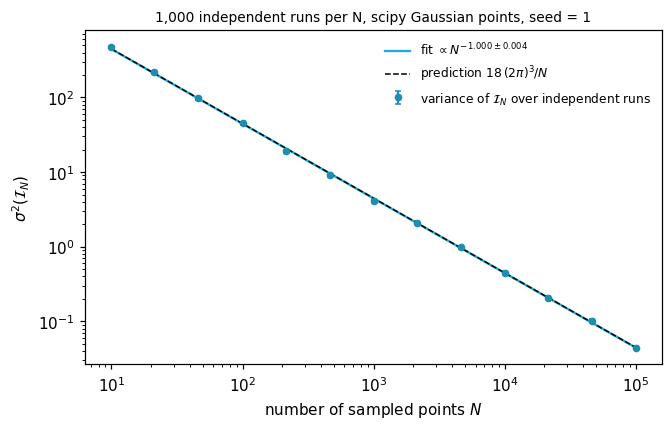

In [31]:
# N_RUNS independent estimates I_N at each N; their spread is the variance of the estimate
I_mean, I_var, I_var_err = variance_vs_n(N_LIST, N_RUNS, rng)
slope, slope_err, prefactor = fit_power_law(N_LIST, I_var, I_var_err)

# prediction: sigma^2(I_N) = (2 pi)^3 Var(f) / N with Var(f) = 18 (x+y+z ~ N(0,3), Var(s^2) = 2*3^2)
VAR_THEORY = NORM**2 * 18

fig = plot_variance(N_LIST, I_var, I_var_err, slope, slope_err, prefactor, VAR_THEORY,
                    title=f"{N_RUNS:,} independent runs per N, scipy Gaussian points, seed = {SEED}")
save_figure(fig, "mc_variance")

print(f"fit:    sigma^2 = {prefactor:.0f} * N^({slope:.3f} ± {slope_err:.3f})")
print(f"theory: sigma^2 = {VAR_THEORY:.0f} / N")
for n, v, dv in zip(N_LIST, I_var, I_var_err):
    print(f"N = {n:>7,}: sigma^2 = {v:9.4f} ± {dv:.4f},   N * sigma^2 = {n * v:5.0f} ± {n * dv:.0f}")

## (d) Why can't we swap the two factors, i.e. use $(x+y+z)^2$ as density and $e^{-r^2/2}$ as integrand?

L =    1: Z =         8,  I_box =   4.376 ±  0.001,  sigma_g/<g> =    0.24
L =  1.5: Z =      60.8,  I_box =  16.944 ±  0.009,  sigma_g/<g> =    0.55
L =    2: Z =       256,  I_box =  31.793 ±  0.032,  sigma_g/<g> =    1.00
L =    3: Z =  1.94e+03,  I_box =  45.681 ±  0.119,  sigma_g/<g> =    2.61
L =    4: Z =  8.19e+03,  I_box =  47.473 ±  0.258,  sigma_g/<g> =    5.44
L =    6: Z =  6.22e+04,  I_box =  47.153 ±  0.724,  sigma_g/<g> =   15.35
L =    8: Z =  2.62e+05,  I_box =  46.377 ±  1.401,  sigma_g/<g> =   30.21
L =   12: Z =  1.99e+06,  I_box =  42.368 ±  3.450,  sigma_g/<g> =   81.42
L =   16: Z =  8.39e+06,  I_box =  44.812 ±  7.449,  sigma_g/<g> =  166.22
exact I = 47.249,  Gaussian density: sigma_f/<f> = 1.414


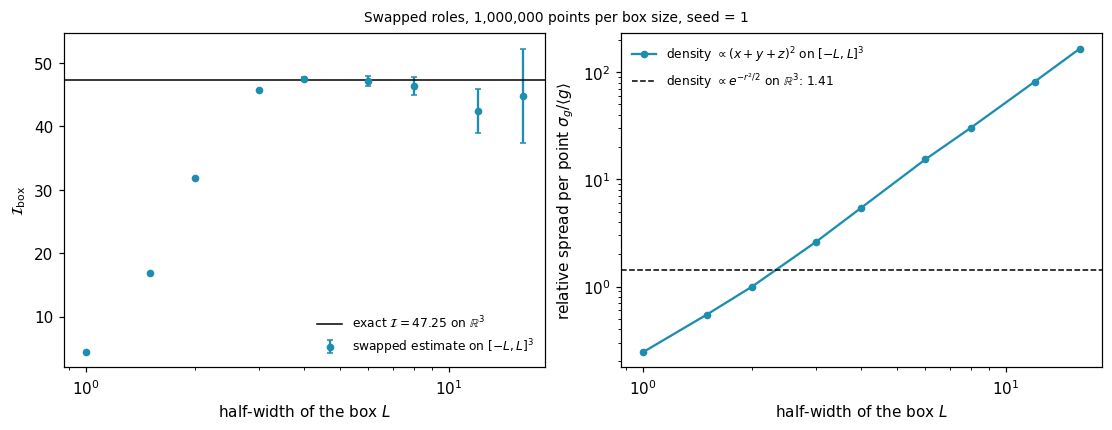

In [32]:
# (x+y+z)^2 has an infinite integral over R^3 -> not a density. Restrict to a box [-L, L]^3:
# density p = s^2 / Z with Z = (2L)^3 L^2, integrand g = Z exp(-r^2/2), I_box = <g>_p
results = np.array([swapped_estimate(N_SWAP, L, rng) for L in L_LIST])
I_box, I_box_err, rel_spread = results.T

# relative spread per point with the Gaussian density: std(f) / mean(f) = sqrt(18) / 3
REL_GAUSS = np.sqrt(18) / 3

fig = plot_swapped(L_LIST, I_box, I_box_err, rel_spread, I_EXACT, REL_GAUSS,
                   title=f"Swapped roles, {N_SWAP:,} points per box size, seed = {SEED}")
save_figure(fig, "mc_swapped")

for L, i, e, r in zip(L_LIST, I_box, I_box_err, rel_spread):
    print(f"L = {L:>4g}: Z = {(2*L)**3 * L**2:9.3g},  I_box = {i:7.3f} ± {e:6.3f},  sigma_g/<g> = {r:7.2f}")
print(f"exact I = {I_EXACT:.3f},  Gaussian density: sigma_f/<f> = {REL_GAUSS:.3f}")